In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import pandas as pd
from aqs import features as F, health as H, plots as P, stats as S
from aqs.config import CITIES

pd.set_option("display.precision", 3)
pd.set_option("display.max_rows", 100)
P.use_theme()
long = F.load_long()
table = S.correlation_table(long)

In [2]:
health = H.health_series(table)
health[["city", "series", "weeks", "raw_r", "deseason_r", "drop", "ci_low", "ci_high", "p_fdr", "significant"]]

,city,series,weeks,raw_r,deseason_r,drop,ci_low,ci_high,p_fdr,significant
0,bangkok,breathing difficulty (Thai),150,0.051,-0.011,0.062,-0.181,0.170,0.930,False
1,bangkok,"chest pain (English, country)",150,-0.069,-0.057,-0.012,-0.188,0.070,0.671,False
2,bangkok,chest pain (Thai),150,0.226,0.130,0.097,-0.050,0.240,0.354,False
3,bangkok,cough medicine (Thai),150,0.081,0.128,-0.048,-0.091,0.291,0.461,False
4,bangkok,"eye drops (English, country)",150,-0.083,0.119,-0.201,0.005,0.250,0.403,False
5,bangkok,eye drops (Thai),150,0.052,0.205,-0.153,0.068,0.357,0.227,False
6,bangkok,"hospital (English, country)",150,-0.007,-0.168,0.161,-0.301,-0.055,0.353,False
7,bangkok,hospital (Thai),150,-0.016,-0.167,0.151,-0.333,-0.020,0.201,False
8,krakow,breathing difficulty (Polish),134,0.250,-0.039,0.289,-0.186,0.113,0.709,False
9,krakow,"chest pain (English, country)",134,0.072,0.056,0.016,-0.153,0.221,0.681,False


In [3]:
H.confound_summary(table)

,city,role,series,median_raw_r,median_deseason_r,max_raw_r,max_deseason_r,significant
0,bangkok,awareness,5,0.659,0.549,0.760,0.650,5
1,bangkok,protection,3,0.604,0.381,0.634,0.444,3
2,bangkok,health,8,0.022,0.054,0.226,0.205,0
3,krakow,awareness,2,0.674,0.532,0.773,0.628,2
4,krakow,protection,2,0.629,0.373,0.633,0.415,2
5,krakow,health,8,0.056,0.054,0.559,0.161,0
6,melbourne,awareness,2,0.204,0.219,0.222,0.268,0
7,melbourne,protection,4,-0.012,0.099,0.050,0.171,0
8,melbourne,health,5,0.154,-0.022,0.165,0.203,0
9,lahore,awareness,2,0.601,0.580,0.601,0.583,2


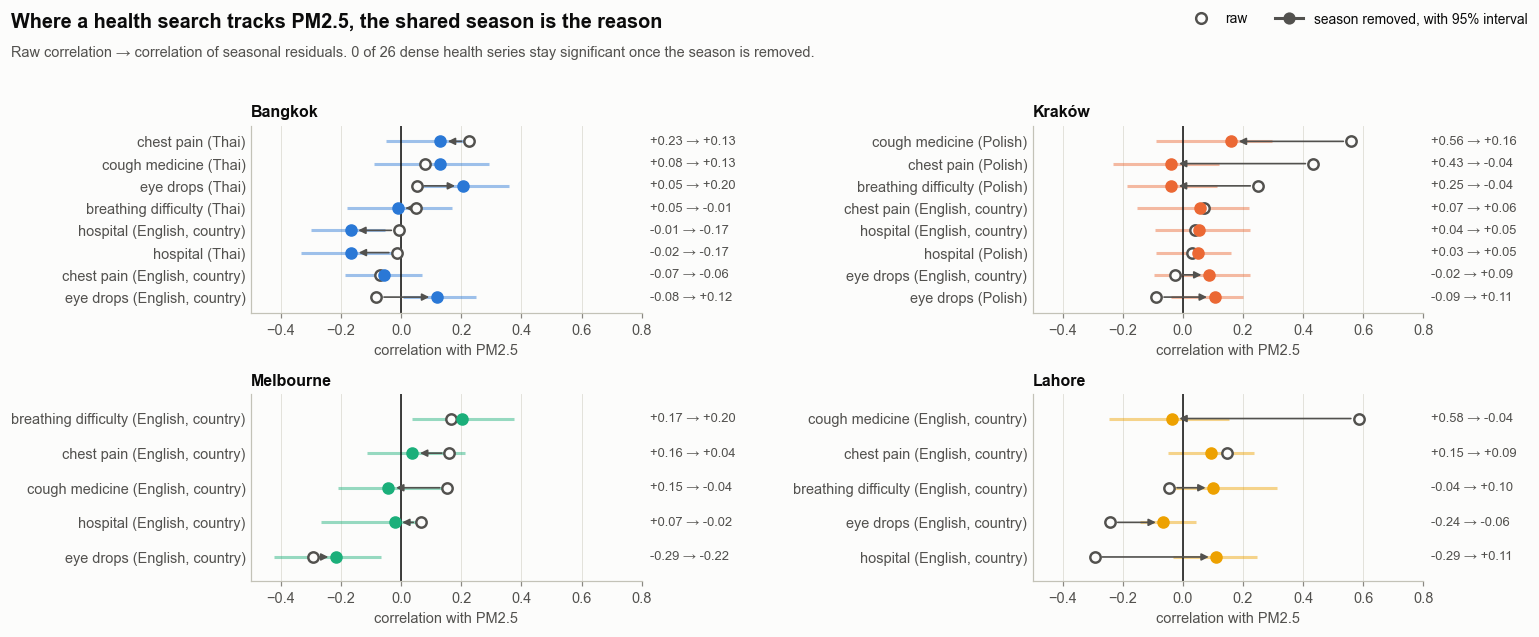

In [4]:
P.health_raw_vs_deseasonalised(health);

In [5]:
contrast = H.role_contrast(table)
contrast[["city", "role", "series", "raw_r", "deseason_r", "drop", "ci_low", "ci_high", "p_fdr", "significant"]]

,city,role,series,raw_r,deseason_r,drop,ci_low,ci_high,p_fdr,significant
0,bangkok,awareness,dust (Thai),0.659,0.511,0.148,0.363,0.642,0.020,True
1,bangkok,protection,air purifier (Thai),0.604,0.381,0.223,0.156,0.574,0.020,True
2,bangkok,health,breathing difficulty (Thai),0.051,-0.011,0.062,-0.181,0.170,0.930,False
3,krakow,awareness,smog (Polish),0.773,0.628,0.144,0.424,0.733,0.020,True
4,krakow,protection,air purifier (Polish),0.633,0.415,0.218,0.191,0.559,0.020,True
5,krakow,health,breathing difficulty (Polish),0.250,-0.039,0.289,-0.186,0.113,0.709,False
6,melbourne,awareness,"air quality (English, region)",0.222,0.170,0.052,-0.035,0.464,0.353,False
7,melbourne,protection,"air purifier (English, region)",-0.070,0.171,-0.241,-0.043,0.342,0.353,False
8,melbourne,health,"breathing difficulty (English, country)",0.165,0.203,-0.038,0.035,0.376,0.337,False
9,lahore,awareness,smog,0.600,0.578,0.023,0.059,0.781,0.020,True


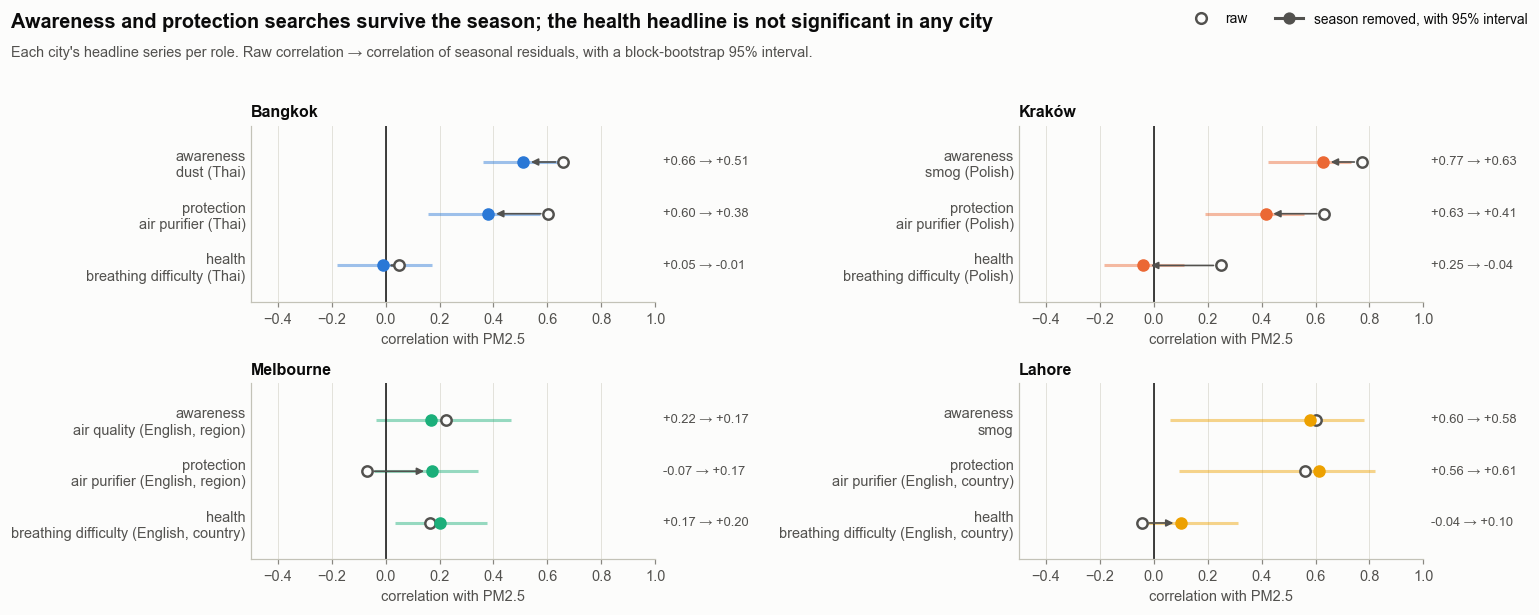

In [6]:
P.health_role_contrast(contrast);

In [7]:
cascade = H.cascade(long)
cascade

,city,role,series,weeks,peak_lag,peak_r,ci_low,ci_high,interior_share,same_week_share
0,bangkok,awareness,dust (Thai),150,0,0.511,0,0,1.000,0.991
1,bangkok,protection,air purifier (Thai),150,0,0.381,-3,0,0.988,0.767
2,bangkok,health,breathing difficulty (Thai),150,-5,0.122,-6,7,0.997,0.045
3,krakow,awareness,smog (Polish),134,0,0.628,0,0,1.000,0.995
4,krakow,protection,air purifier (Polish),134,0,0.415,-7,0,1.000,0.870
5,krakow,health,breathing difficulty (Polish),134,-5,0.115,<NA>,<NA>,0.931,0.001
6,melbourne,awareness,"air quality (English, region)",96,<NA>,NaN,<NA>,1,0.211,0.085
7,melbourne,protection,"air purifier (English, region)",96,-7,0.309,-7,0,0.982,0.081
8,melbourne,health,"breathing difficulty (English, country)",96,-6,0.206,<NA>,<NA>,0.877,0.356
9,lahore,awareness,smog,123,1,0.580,-7,4,1.000,0.430


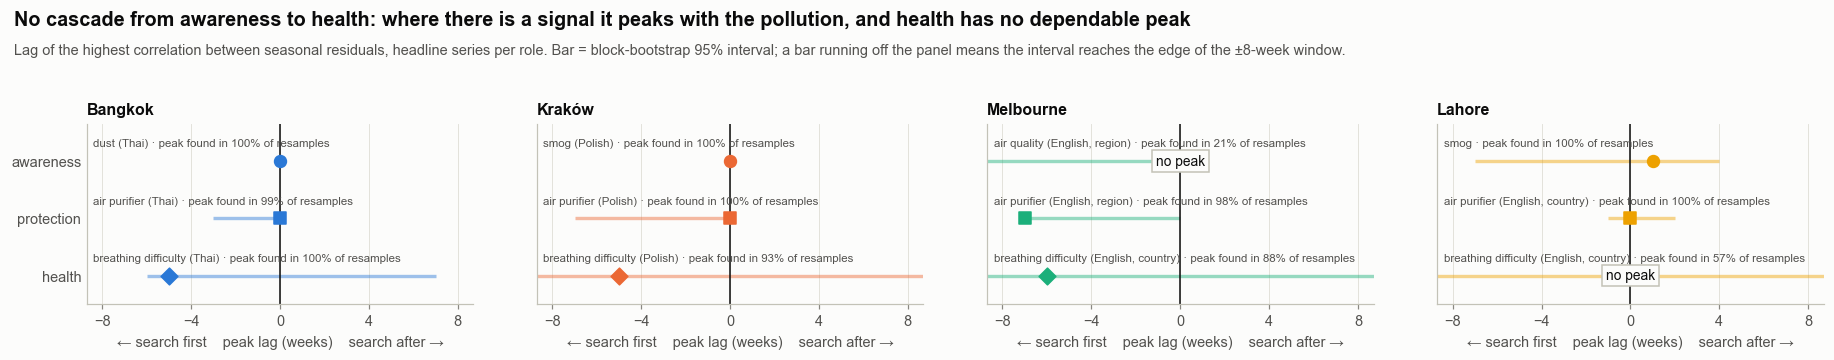

In [8]:
P.health_cascade(cascade);

In [9]:
yoy = H.yoy(long)
yoy.pivot_table(index=["city", "role"], columns="year", values="deseason_r", sort=False, dropna=False)

year                   2022   2023   2024
city      role                           
bangkok   awareness   0.472  0.443  0.712
          protection  0.361  0.335  0.645
          health      0.032  0.173 -0.103
krakow    awareness   0.543  0.572  0.745
          protection  0.496 -0.013  0.512
          health      0.002 -0.107 -0.061
melbourne awareness  -0.027    NaN  0.350
          protection  0.127    NaN  0.184
          health      0.147    NaN  0.255
lahore    awareness   0.571  0.046  0.736
          protection  0.512  0.089  0.764
          health     -0.121  0.112  0.215

In [10]:
yoy[yoy["skipped"]]

,city,role,series,year,weeks,skipped,deseason_r
19,melbourne,awareness,"air quality (English, region)",2023,7,True,NaN
22,melbourne,protection,"air purifier (English, region)",2023,7,True,NaN
25,melbourne,health,"breathing difficulty (English, country)",2023,7,True,NaN


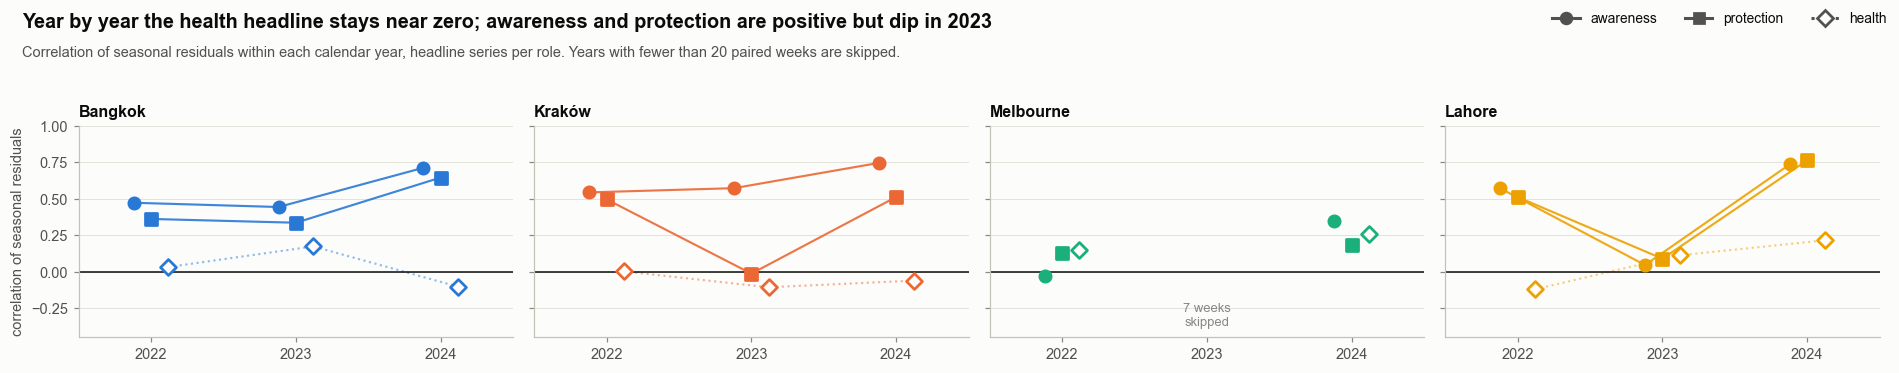

In [11]:
P.health_yoy(yoy);

In [12]:
matrices = H.summary_matrices(table)
matrices["deseason_r"].round(2)

city                                              bangkok  krakow  melbourne  \
role       slot                                                                
attention  attention index (PC1)                     0.53    0.58       0.07   
awareness  air quality (English, country)            0.55    0.44       0.27   
           air quality (English, region)             0.65     NaN       0.17   
           air quality (local language)              0.30     NaN        NaN   
           PM2.5 (local usage)                       0.61     NaN        NaN   
           smog / dust (local term)                  0.51    0.63        NaN   
protection air purifier (English, country)           0.33    0.33       0.07   
           air purifier (English, region)            0.44     NaN       0.17   
           air purifier (local language)             0.38    0.41        NaN   
           mask (local term)                          NaN     NaN        NaN   
           N95 mask (English, country)                NaN     NaN       0.10   
           N95 mask (English, region)                 NaN     NaN       0.10   
health     breathing difficulty (English)             NaN     NaN       0.20   
           breathing difficulty (local language)    -0.01   -0.04        NaN   
           chest pain (English)                     -0.06    0.06       0.04   
           chest pain (local language)               0.13   -0.04        NaN   
           cough medicine (English)                   NaN     NaN      -0.04   
           cough medicine (local language)           0.13    0.16        NaN   
           eye drops (English)                       0.12    0.09      -0.22   
           eye drops (local language)                0.20    0.11        NaN   
           hospital (English)                       -0.17    0.05      -0.02   
           hospital (local language)                -0.17    0.05        NaN   

city                                              lahore  
role       slot                                           
attention  attention index (PC1)                    0.59  
awareness  air quality (English, country)           0.58  
           air quality (English, region)             NaN  
           air quality (local language)              NaN  
           PM2.5 (local usage)                       NaN  
           smog / dust (local term)                 0.58  
protection air purifier (English, country)          0.61  
           air purifier (English, region)            NaN  
           air purifier (local language)             NaN  
           mask (local term)                        0.20  
           N95 mask (English, country)               NaN  
           N95 mask (English, region)                NaN  
health     breathing difficulty (English)           0.10  
           breathing difficulty (local language)     NaN  
           chest pain (English)                     0.09  
           chest pain (local language)               NaN  
           cough medicine (English)                -0.04  
           cough medicine (local language)           NaN  
           eye drops (English)                     -0.06  
           eye drops (local language)                NaN  
           hospital (English)                       0.11  
           hospital (local language)                 NaN

In [13]:
matrices["peak_lag"].astype("Int64")

city                                              bangkok  krakow  melbourne  \
role       slot                                                                
attention  attention index (PC1)                        0       0         -7   
awareness  air quality (English, country)               0       0       <NA>   
           air quality (English, region)                0    <NA>       <NA>   
           air quality (local language)                 0    <NA>       <NA>   
           PM2.5 (local usage)                          0    <NA>       <NA>   
           smog / dust (local term)                     0       0       <NA>   
protection air purifier (English, country)              0       0         -7   
           air purifier (English, region)               0    <NA>         -7   
           air purifier (local language)                0       0       <NA>   
           mask (local term)                         <NA>    <NA>       <NA>   
           N95 mask (English, country)               <NA>    <NA>       <NA>   
           N95 mask (English, region)                <NA>    <NA>         -7   
health     breathing difficulty (English)            <NA>    <NA>         -6   
           breathing difficulty (local language)       -5      -5       <NA>   
           chest pain (English)                         6    <NA>         -7   
           chest pain (local language)                  0    <NA>       <NA>   
           cough medicine (English)                  <NA>    <NA>         -6   
           cough medicine (local language)             -3       1       <NA>   
           eye drops (English)                          0    <NA>          4   
           eye drops (local language)                  -1       6       <NA>   
           hospital (English)                        <NA>       7         -7   
           hospital (local language)                 <NA>       5       <NA>   

city                                              lahore  
role       slot                                           
attention  attention index (PC1)                       0  
awareness  air quality (English, country)              0  
           air quality (English, region)            <NA>  
           air quality (local language)             <NA>  
           PM2.5 (local usage)                      <NA>  
           smog / dust (local term)                    1  
protection air purifier (English, country)             0  
           air purifier (English, region)           <NA>  
           air purifier (local language)            <NA>  
           mask (local term)                           0  
           N95 mask (English, country)              <NA>  
           N95 mask (English, region)               <NA>  
health     breathing difficulty (English)           <NA>  
           breathing difficulty (local language)    <NA>  
           chest pain (English)                       -3  
           chest pain (local language)              <NA>  
           cough medicine (English)                   -3  
           cough medicine (local language)          <NA>  
           eye drops (English)                        -6  
           eye drops (local language)               <NA>  
           hospital (English)                         -1  
           hospital (local language)                <NA>

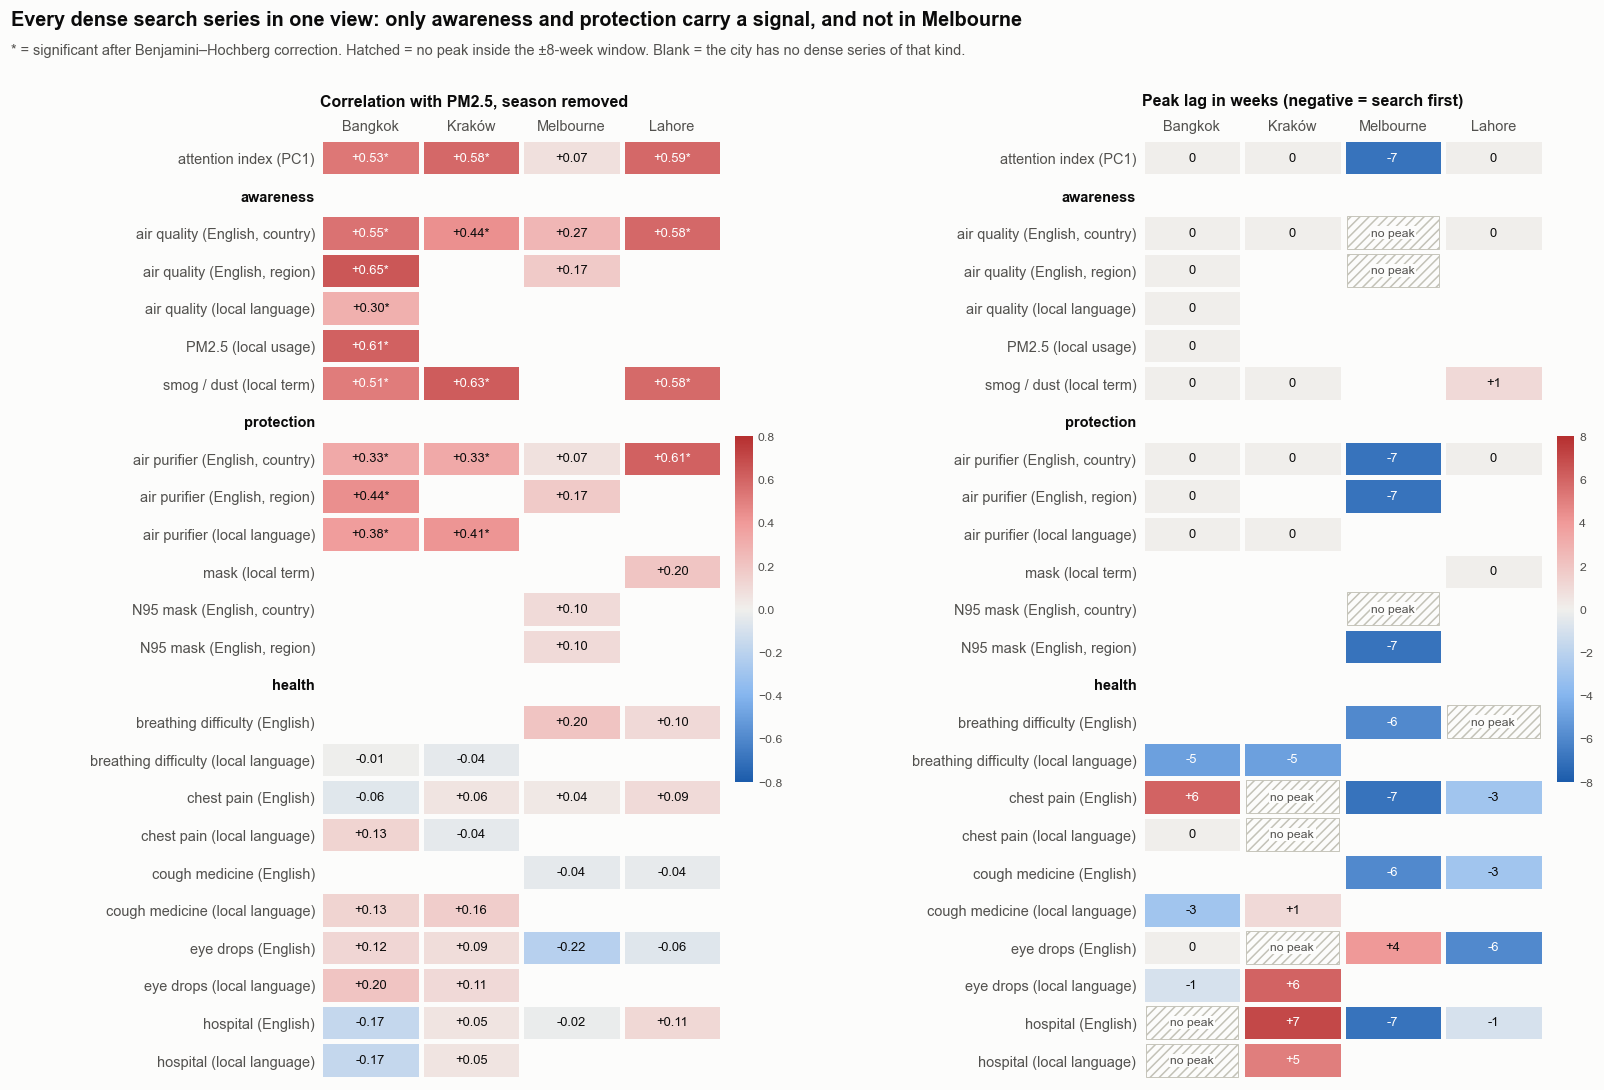

In [14]:
P.health_summary_matrix(matrices);